### Machine Learning Unsupervised Algorithms

#### Keith R. Holdaway FGS

Simple Rock Typing with Unsupervised Learning


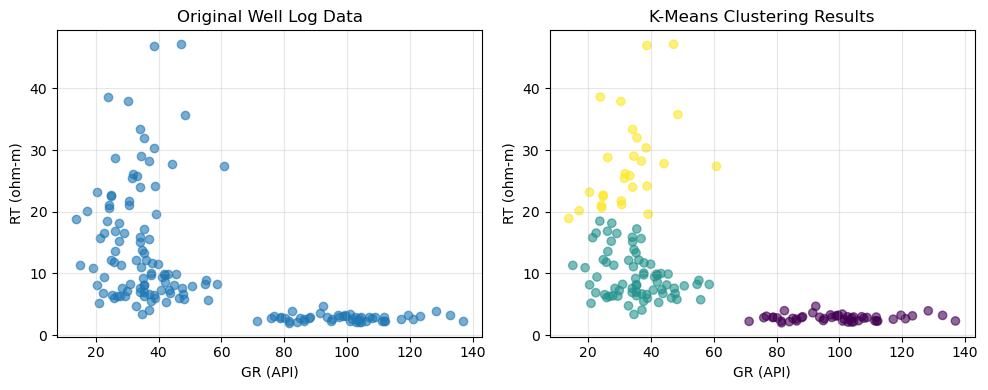

AI automatically identified 3 rock types from GR and RT logs!
No labels needed - the algorithm found patterns by itself!


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

print("Simple Rock Typing with Unsupervised Learning")

# Tiny dataset - 3 rock types
np.random.seed(42)
n_samples = 150

# Sandstone: Low GR, Medium RT
sandstone = np.column_stack([
    np.random.normal(40, 10, n_samples//3),      # GR
    np.random.lognormal(2.0, 0.3, n_samples//3)  # RT
])

# Shale: High GR, Low RT  
shale = np.column_stack([
    np.random.normal(100, 15, n_samples//3),     # GR
    np.random.lognormal(1.0, 0.2, n_samples//3)  # RT
])

# Limestone: Low GR, High RT
limestone = np.column_stack([
    np.random.normal(30, 8, n_samples//3),       # GR  
    np.random.lognormal(3.0, 0.4, n_samples//3)  # RT
])

X = np.vstack([sandstone, shale, limestone])

# K-Means Clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)

# Visualize
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], alpha=0.6)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title('Original Well Log Data')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.6)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title('K-Means Clustering Results')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("AI automatically identified 3 rock types from GR and RT logs!")
print("No labels needed - the algorithm found patterns by itself!")

In [2]:
pip install minisom

Note: you may need to restart the kernel to use updated packages.


🧠 SOM & GMM Unsupervised Learning for Petrophysicists

 Creating realistic well log dataset...
Created dataset with 500 samples
Rock types: ['Clean Sandstone', 'Shaly Sand', 'Shale', 'Limestone', 'Dolomite']

🔍 Exploring dataset characteristics...


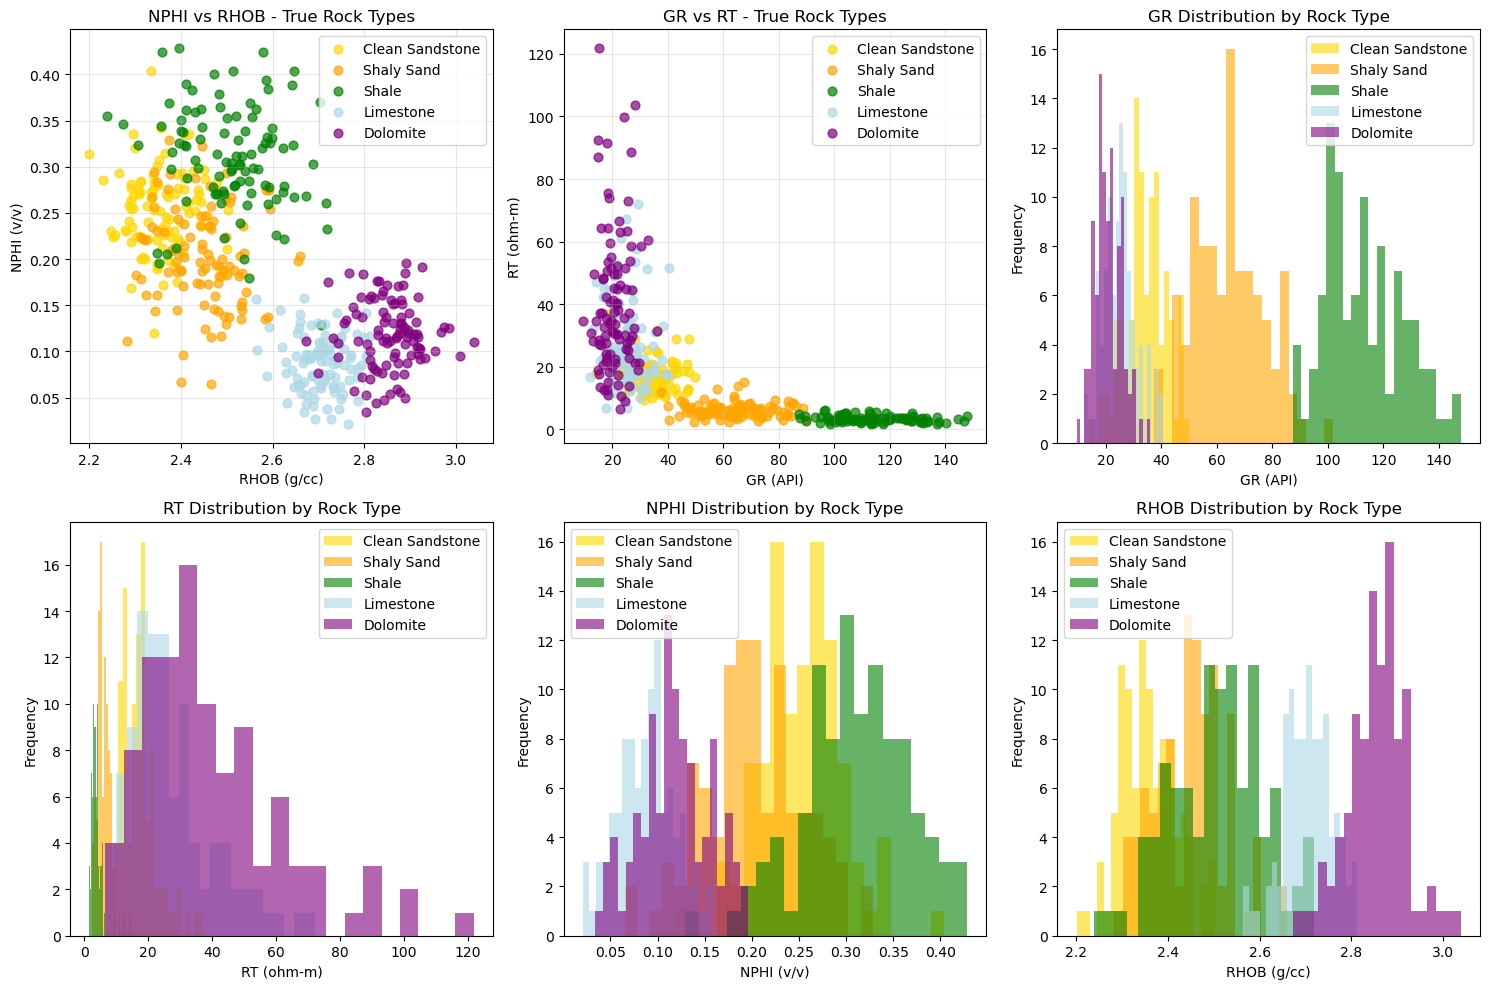


⚙️ Preparing data for SOM and GMM...
Data scaled and ready for analysis

🎯 SELF-ORGANIZING MAPS (SOM) ANALYSIS
Training SOM...
SOM trained with 10x10 map (100 total neurons)


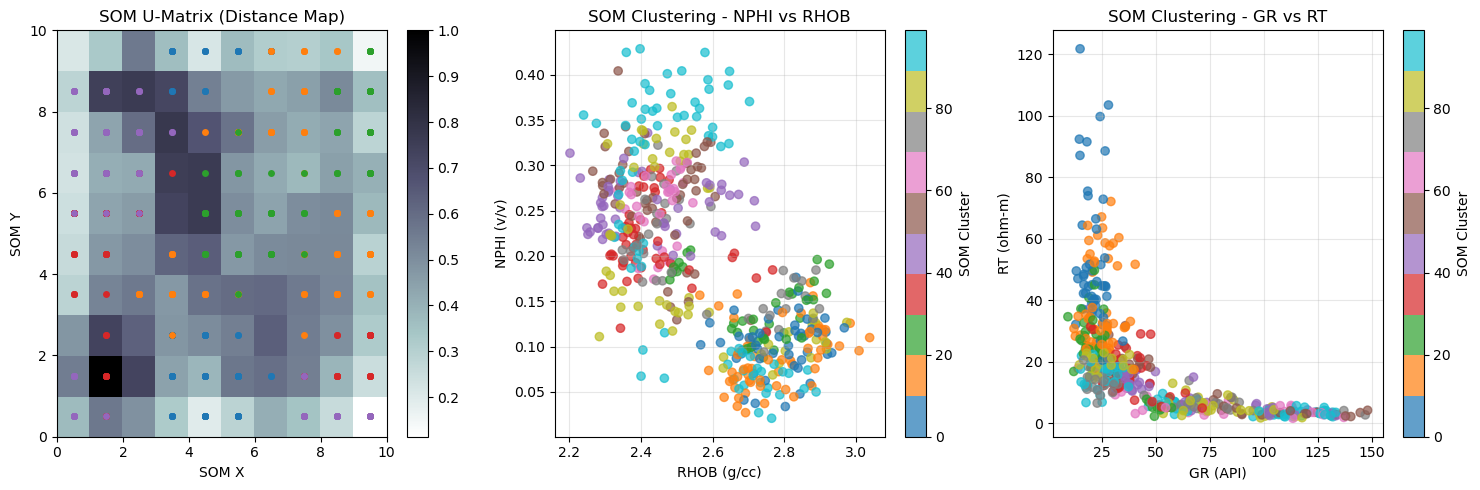


🎯 GAUSSIAN MIXTURE MODELS (GMM) ANALYSIS
Finding optimal number of Gaussian components...
Optimal number of components: 4 (based on BIC)
GMM trained with 4 components


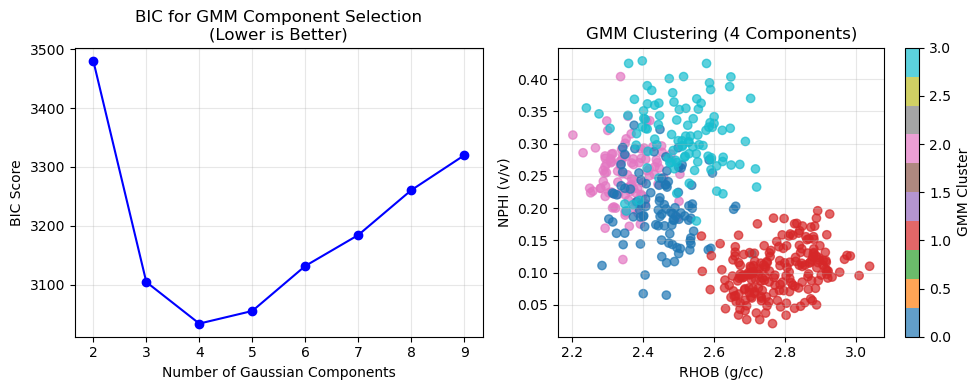


 COMPARING SOM vs GMM PERFORMANCE
SOM Silhouette Score: 0.160
GMM Silhouette Score: 0.428
(Higher is better, range: -1 to +1)


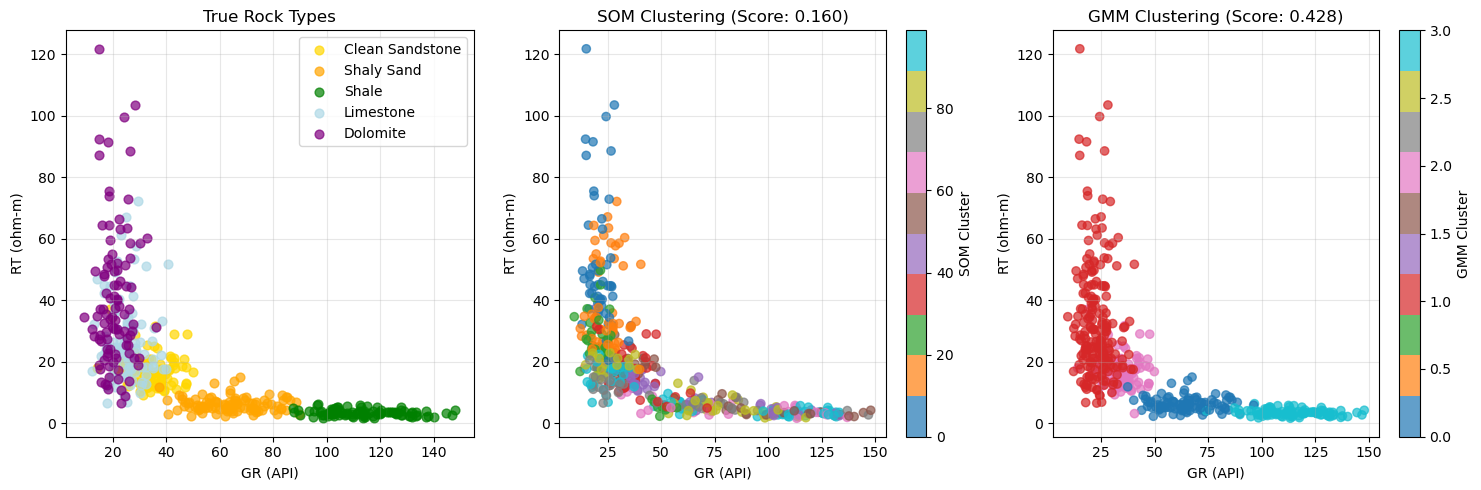


 DETAILED CLUSTER CHARACTERISTICS

 GMM Cluster Centers (Original Scale):
       GR     RT  NPHI  RHOB
0   64.88   6.23  0.20  2.45
1   23.03  33.59  0.10  2.78
2   34.42  16.99  0.25  2.36
3  112.97   3.48  0.31  2.51

📊 GMM Cluster Statistics:

Cluster 0 (98 samples, Avg Confidence: 0.958):
  GR:      64.4 ± 12.5 API
  RT:       6.3 ±  2.3 ohm-m
  NPHI:    0.20 ± 0.05 v/v
  RHOB:    2.45 ± 0.08 g/cc

Cluster 1 (200 samples, Avg Confidence: 0.998):
  GR:      23.0 ±  5.8 API
  RT:      33.6 ± 19.7 ohm-m
  NPHI:    0.10 ± 0.04 v/v
  RHOB:    2.78 ± 0.09 g/cc

Cluster 2 (101 samples, Avg Confidence: 0.996):
  GR:      34.2 ±  7.3 API
  RT:      17.1 ±  5.5 ohm-m
  NPHI:    0.25 ± 0.04 v/v
  RHOB:    2.36 ± 0.06 g/cc

Cluster 3 (101 samples, Avg Confidence: 0.984):
  GR:     113.1 ± 14.5 API
  RT:       3.5 ±  1.0 ohm-m
  NPHI:    0.31 ± 0.06 v/v
  RHOB:    2.51 ± 0.10 g/cc

💡 PETROPHYSICAL INTERPRETATION

 SOM Advantages:
• Preserves topological relationships between rock types
• Great

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import seaborn as sns

print("🧠 SOM & GMM Unsupervised Learning for Petrophysicists")
print("=" * 60)

# 1. CREATE REALISTIC PETROPHYSICAL DATASET
print("\n Creating realistic well log dataset...")

np.random.seed(42)
n_samples = 500

# Define 5 distinct rock types with realistic log responses
rock_types = {
    0: {'name': 'Clean Sandstone', 'color': 'gold', 'gr_mean': 35, 'gr_std': 8, 'rt_mean': 2.8, 'rt_std': 0.3, 'nphi_mean': 0.25, 'nphi_std': 0.04, 'rhob_mean': 2.35, 'rhob_std': 0.07},
    1: {'name': 'Shaly Sand', 'color': 'orange', 'gr_mean': 65, 'gr_std': 12, 'rt_mean': 1.8, 'rt_std': 0.4, 'nphi_mean': 0.20, 'nphi_std': 0.05, 'rhob_mean': 2.45, 'rhob_std': 0.08},
    2: {'name': 'Shale', 'color': 'green', 'gr_mean': 110, 'gr_std': 15, 'rt_mean': 1.2, 'rt_std': 0.3, 'nphi_mean': 0.30, 'nphi_std': 0.06, 'rhob_mean': 2.50, 'rhob_std': 0.09},
    3: {'name': 'Limestone', 'color': 'lightblue', 'gr_mean': 25, 'gr_std': 6, 'rt_mean': 3.2, 'rt_std': 0.5, 'nphi_mean': 0.08, 'nphi_std': 0.03, 'rhob_mean': 2.71, 'rhob_std': 0.05},
    4: {'name': 'Dolomite', 'color': 'purple', 'gr_mean': 20, 'gr_std': 5, 'rt_mean': 3.5, 'rt_std': 0.6, 'nphi_mean': 0.12, 'nphi_std': 0.04, 'rhob_mean': 2.85, 'rhob_std': 0.06}
}

# Generate data for each rock type
data_list = []
true_labels = []

for rock_id, properties in rock_types.items():
    n_rock_samples = n_samples // len(rock_types)
    
    gr = np.random.normal(properties['gr_mean'], properties['gr_std'], n_rock_samples)
    rt = np.random.lognormal(properties['rt_mean'], properties['rt_std'], n_rock_samples)
    nphi = np.random.normal(properties['nphi_mean'], properties['nphi_std'], n_rock_samples)
    rhob = np.random.normal(properties['rhob_mean'], properties['rhob_std'], n_rock_samples)
    
    for i in range(n_rock_samples):
        data_list.append([gr[i], rt[i], nphi[i], rhob[i]])
        true_labels.append(rock_id)

# Create DataFrame
data = pd.DataFrame(data_list, columns=['GR', 'RT', 'NPHI', 'RHOB'])
data['True_Rock_Type'] = true_labels

print(f"Created dataset with {len(data)} samples")
print(f"Rock types: {[rock_types[i]['name'] for i in range(len(rock_types))]}")

# 2. EXPLORE THE DATASET
print("\n🔍 Exploring dataset characteristics...")

plt.figure(figsize=(15, 10))

# Crossplot 1: NPHI vs RHOB
plt.subplot(2, 3, 1)
for rock_id in rock_types:
    mask = data['True_Rock_Type'] == rock_id
    plt.scatter(data.loc[mask, 'RHOB'], data.loc[mask, 'NPHI'], 
               c=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'], 
               alpha=0.7, s=40)
plt.xlabel('RHOB (g/cc)')
plt.ylabel('NPHI (v/v)')
plt.title('NPHI vs RHOB - True Rock Types')
plt.legend()
plt.grid(True, alpha=0.3)

# Crossplot 2: GR vs RT
plt.subplot(2, 3, 2)
for rock_id in rock_types:
    mask = data['True_Rock_Type'] == rock_id
    plt.scatter(data.loc[mask, 'GR'], data.loc[mask, 'RT'], 
               c=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'], 
               alpha=0.7, s=40)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title('GR vs RT - True Rock Types')
plt.legend()
plt.grid(True, alpha=0.3)

# Log distributions
plt.subplot(2, 3, 3)
for rock_id in rock_types:
    rock_data = data[data['True_Rock_Type'] == rock_id]
    plt.hist(rock_data['GR'], bins=20, alpha=0.6, 
             color=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'])
plt.xlabel('GR (API)')
plt.ylabel('Frequency')
plt.title('GR Distribution by Rock Type')
plt.legend()

plt.subplot(2, 3, 4)
for rock_id in rock_types:
    rock_data = data[data['True_Rock_Type'] == rock_id]
    plt.hist(rock_data['RT'], bins=20, alpha=0.6, 
             color=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'])
plt.xlabel('RT (ohm-m)')
plt.ylabel('Frequency')
plt.title('RT Distribution by Rock Type')
plt.legend()

plt.subplot(2, 3, 5)
for rock_id in rock_types:
    rock_data = data[data['True_Rock_Type'] == rock_id]
    plt.hist(rock_data['NPHI'], bins=20, alpha=0.6, 
             color=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'])
plt.xlabel('NPHI (v/v)')
plt.ylabel('Frequency')
plt.title('NPHI Distribution by Rock Type')
plt.legend()

plt.subplot(2, 3, 6)
for rock_id in rock_types:
    rock_data = data[data['True_Rock_Type'] == rock_id]
    plt.hist(rock_data['RHOB'], bins=20, alpha=0.6, 
             color=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'])
plt.xlabel('RHOB (g/cc)')
plt.ylabel('Frequency')
plt.title('RHOB Distribution by Rock Type')
plt.legend()

plt.tight_layout()
plt.show()

# 3. PREPARE DATA FOR UNSUPERVISED LEARNING
print("\n⚙️ Preparing data for SOM and GMM...")

X = data[['GR', 'RT', 'NPHI', 'RHOB']].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data scaled and ready for analysis")

# 4. SELF-ORGANIZING MAPS (SOM) ANALYSIS
print("\n🎯 SELF-ORGANIZING MAPS (SOM) ANALYSIS")
print("=" * 40)

# Create SOM
print("Training SOM...")
som_x, som_y = 10, 10
som = MiniSom(som_x, som_y, X_scaled.shape[1], sigma=1.0, learning_rate=0.5, 
              neighborhood_function='gaussian', random_seed=42)

# Initialize weights
som.random_weights_init(X_scaled)

# Train SOM
som.train_random(X_scaled, 1000, verbose=False)

# Get SOM results
som_winner_coordinates = np.array([som.winner(x) for x in X_scaled])
som_clusters = som_winner_coordinates[:, 0] * som_y + som_winner_coordinates[:, 1]
data['SOM_Cluster'] = som_clusters

print(f"SOM trained with {som_x}x{som_y} map ({som_x*som_y} total neurons)")

# Visualize SOM results
plt.figure(figsize=(15, 5))

# SOM U-Matrix
plt.subplot(1, 3, 1)
plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar()
plt.title('SOM U-Matrix (Distance Map)')
for i, (x, y) in enumerate(som_winner_coordinates):
    plt.plot(x + 0.5, y + 0.5, 'o', markerfacecolor=plt.cm.tab10(true_labels[i] % 10), 
             markersize=5, markeredgewidth=0)
plt.xlabel('SOM X')
plt.ylabel('SOM Y')

# SOM clustering results
plt.subplot(1, 3, 2)
scatter = plt.scatter(data['RHOB'], data['NPHI'], c=som_clusters, cmap='tab10', alpha=0.7)
plt.xlabel('RHOB (g/cc)')
plt.ylabel('NPHI (v/v)')
plt.title('SOM Clustering - NPHI vs RHOB')
plt.colorbar(scatter, label='SOM Cluster')
plt.grid(True, alpha=0.3)

# SOM clustering results - GR vs RT
plt.subplot(1, 3, 3)
scatter = plt.scatter(data['GR'], data['RT'], c=som_clusters, cmap='tab10', alpha=0.7)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title('SOM Clustering - GR vs RT')
plt.colorbar(scatter, label='SOM Cluster')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5. GAUSSIAN MIXTURE MODELS (GMM) ANALYSIS
print("\n🎯 GAUSSIAN MIXTURE MODELS (GMM) ANALYSIS")
print("=" * 40)

# Find optimal number of components using BIC
print("Finding optimal number of Gaussian components...")
n_components_range = range(2, 10)
bic_scores = []
gmm_models = []

for n_components in n_components_range:
    gmm = GaussianMixture(n_components=n_components, random_state=42, covariance_type='full')
    gmm.fit(X_scaled)
    bic_scores.append(gmm.bic(X_scaled))
    gmm_models.append(gmm)

# Plot BIC scores
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(n_components_range, bic_scores, 'bo-')
plt.xlabel('Number of Gaussian Components')
plt.ylabel('BIC Score')
plt.title('BIC for GMM Component Selection\n(Lower is Better)')
plt.grid(True, alpha=0.3)

# Choose optimal number (minimum BIC)
optimal_n_components = n_components_range[np.argmin(bic_scores)]
print(f"Optimal number of components: {optimal_n_components} (based on BIC)")

# Train final GMM with optimal components
final_gmm = GaussianMixture(n_components=optimal_n_components, random_state=42, covariance_type='full')
gmm_labels = final_gmm.fit_predict(X_scaled)
gmm_probs = final_gmm.predict_proba(X_scaled)

data['GMM_Cluster'] = gmm_labels
data['GMM_Confidence'] = np.max(gmm_probs, axis=1)

print(f"GMM trained with {optimal_n_components} components")

# Visualize GMM results
plt.subplot(1, 2, 2)
scatter = plt.scatter(data['RHOB'], data['NPHI'], c=gmm_labels, cmap='tab10', alpha=0.7)
plt.xlabel('RHOB (g/cc)')
plt.ylabel('NPHI (v/v)')
plt.title(f'GMM Clustering ({optimal_n_components} Components)')
plt.colorbar(scatter, label='GMM Cluster')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 6. COMPARE SOM vs GMM RESULTS
print("\n COMPARING SOM vs GMM PERFORMANCE")
print("=" * 40)

# Calculate silhouette scores
som_silhouette = silhouette_score(X_scaled, som_clusters)
gmm_silhouette = silhouette_score(X_scaled, gmm_labels)

print(f"SOM Silhouette Score: {som_silhouette:.3f}")
print(f"GMM Silhouette Score: {gmm_silhouette:.3f}")
print("(Higher is better, range: -1 to +1)")

# Compare clustering results
plt.figure(figsize=(15, 5))

# SOM vs True labels
plt.subplot(1, 3, 1)
for rock_id in rock_types:
    mask = data['True_Rock_Type'] == rock_id
    plt.scatter(data.loc[mask, 'GR'], data.loc[mask, 'RT'], 
               c=rock_types[rock_id]['color'], label=rock_types[rock_id]['name'], 
               alpha=0.7, s=40)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title('True Rock Types')
plt.legend()
plt.grid(True, alpha=0.3)

# SOM clustering
plt.subplot(1, 3, 2)
scatter = plt.scatter(data['GR'], data['RT'], c=som_clusters, cmap='tab10', alpha=0.7)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title(f'SOM Clustering (Score: {som_silhouette:.3f})')
plt.colorbar(scatter, label='SOM Cluster')
plt.grid(True, alpha=0.3)

# GMM clustering
plt.subplot(1, 3, 3)
scatter = plt.scatter(data['GR'], data['RT'], c=gmm_labels, cmap='tab10', alpha=0.7)
plt.xlabel('GR (API)')
plt.ylabel('RT (ohm-m)')
plt.title(f'GMM Clustering (Score: {gmm_silhouette:.3f})')
plt.colorbar(scatter, label='GMM Cluster')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 7. DETAILED CLUSTER ANALYSIS
print("\n DETAILED CLUSTER CHARACTERISTICS")

print("\n GMM Cluster Centers (Original Scale):")
gmm_centers_scaled = final_gmm.means_
gmm_centers_original = scaler.inverse_transform(gmm_centers_scaled)

centers_df = pd.DataFrame(gmm_centers_original, columns=['GR', 'RT', 'NPHI', 'RHOB'])
print(centers_df.round(2))

# Analyze GMM cluster characteristics
print("\n📊 GMM Cluster Statistics:")
for cluster_id in range(optimal_n_components):
    cluster_data = data[data['GMM_Cluster'] == cluster_id]
    confidence = cluster_data['GMM_Confidence'].mean()
    
    print(f"\nCluster {cluster_id} ({len(cluster_data)} samples, Avg Confidence: {confidence:.3f}):")
    print(f"  GR:    {cluster_data['GR'].mean():6.1f} ± {cluster_data['GR'].std():4.1f} API")
    print(f"  RT:    {cluster_data['RT'].mean():6.1f} ± {cluster_data['RT'].std():4.1f} ohm-m")
    print(f"  NPHI:  {cluster_data['NPHI'].mean():6.2f} ± {cluster_data['NPHI'].std():4.2f} v/v")
    print(f"  RHOB:  {cluster_data['RHOB'].mean():6.2f} ± {cluster_data['RHOB'].std():4.2f} g/cc")

# 8. PETROPHYSICAL INTERPRETATION
print("\n💡 PETROPHYSICAL INTERPRETATION")

print("\n SOM Advantages:")
print("• Preserves topological relationships between rock types")
print("• Great for visualization and pattern recognition")
print("• Can identify transitional zones between facies")
print("• No need to pre-specify number of clusters")

print("\n GMM Advantages:")
print("• Provides probabilistic cluster assignments")
print("• Handles overlapping distributions well")
print("• Gives confidence measures for predictions")
print("• Automatically determines cluster shapes")

print("\n Practical Recommendations:")
print("• Use SOM for exploratory data analysis and visualization")
print("• Use GMM when you need probabilistic results and confidence measures")
print("• Combine both for comprehensive understanding")

# 9. APPLY TO NEW DATA
print("\n APPLYING MODELS TO NEW WELL LOGS")

new_logs = np.array([
    [40, 25, 0.24, 2.38],   # Clean sandstone
    [70, 12, 0.19, 2.48],   # Shaly sand
    [105, 8, 0.28, 2.52],   # Shale
    [28, 45, 0.07, 2.70],   # Limestone
    [22, 60, 0.11, 2.83],   # Dolomite
])

new_logs_scaled = scaler.transform(new_logs)

# SOM predictions
som_winners = np.array([som.winner(x) for x in new_logs_scaled])
som_predictions = som_winners[:, 0] * som_y + som_winners[:, 1]

# GMM predictions
gmm_predictions = final_gmm.predict(new_logs_scaled)
gmm_confidences = np.max(final_gmm.predict_proba(new_logs_scaled), axis=1)

print("\n New Log Predictions:")
print("GR    RT    NPHI  RHOB  →  SOM Cluster  GMM Cluster  Confidence")
print("-" * 70)
for i in range(len(new_logs)):
    print(f"{new_logs[i,0]:3.0f}  {new_logs[i,1]:3.0f}  {new_logs[i,2]:4.2f}  {new_logs[i,3]:4.2f}  "
          f"→      {som_predictions[i]:2.0f}           {gmm_predictions[i]:1.0f}         {gmm_confidences[i]:.3f}")

print("\n SOM and GMM Analysis Complete!")
print("💡 Both methods successfully identified rock types from well logs!")